In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xesmf as xe
import seaborn as sns
from matplotlib import rcParams
sns.set_style('whitegrid')
import matplotlib
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import rcParams
import cmocean

In [2]:
# made in variability_regression_ensoremoved
cwd = %pwd
noise1=xr.open_dataset(cwd+"/data/variability_sigma_2000to2025_sst_oct2026.nc").sigma #we checked this is exactly the same as "/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/variability_sigma_2000to2025_sst.nc"
noise2=xr.open_dataset(cwd+"/data/variability_sigma_2075to2100_sst_oct2026.nc").sigma

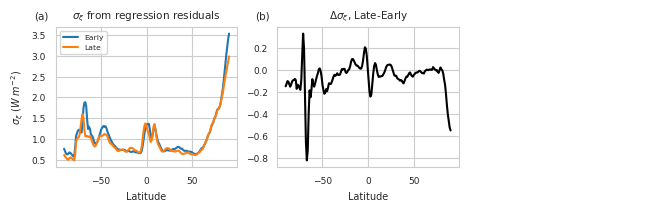

In [3]:
from matplotlib import rcParams

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})


fig,((ax1,ax2,ax3))=plt.subplots(1,3,figsize=(6.47,2),constrained_layout=True)

noise1.plot(ax=ax1)
noise2.plot(ax=ax1)
ax1.set_title(r'$\sigma_\xi$ from regression residuals')
ax1.set_xlabel('Latitude')
ax1.set_ylabel(r'$\sigma_\xi$ ($W$ $m^{-2})$')
ax1.legend(['Early','Late'])
ax1.set_title('(a)',loc='left',x=-0.12)



(noise2-noise1).plot(ax=ax2,color='black')
ax2.set_title(r'$\Delta \sigma_\xi$, Late-Early')
ax2.set_xlabel('Latitude')
ax2.set_ylabel('')
ax2.set_title('(b)',loc='left',x=-0.12)

ax3.axis('off') 

ax3.set_title('')
ax3.set_xlabel('')

import matplotlib
matplotlib.pyplot.savefig('noiseinjection_regression_sstupdate.png', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)

# Heat cap

In [4]:
temp_sat=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_trefht_40members_CESM1.nc')
temp_sat=temp_sat.__xarray_dataarray_variable__
cesm_temps_mean=temp_sat.mean('ensemble_member')


ds_out = xr.Dataset(
    {
        "lat": (["lat"],np.linspace(-90,90,180), {"units": "degrees_north"}),
        "lon": (["lon"], np.linspace(-180,180,180), {"units": "degrees_east"}),
    }
)
ds_out

ice=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_ifrac_40members_CESM1.nc').__xarray_dataarray_variable__


regridder=xe.Regridder(ice,ds_out, method="nearest_s2d", periodic=True, reuse_weights=False,ignore_degenerate=True)
regridded_ice=regridder(ice)

landmask = xr.where(regridded_ice[0,0,:,:].isnull(), 1, 0)


is_polar_land = (landmask == 1) & (
    (landmask.lat < -55) | #checked and this is the same if i had done -60 instead
    ((landmask.lat > 68) & (landmask.lon > -72) & (landmask.lon < -15)) | #upper part of greenland
    ((landmask.lat < 68) & (landmask.lat > 60) & (landmask.lon > -55) & (landmask.lon < -28))#lower part of greenland
)

# Force ice to 1.0 only on those specific polar land pixels
# This makes the heatcap to use ice_heatcap instead of land_heatcap there
ice_adjusted = xr.where(is_polar_land, 1.0, regridded_ice)


def heatcap(cw,ice,factor,landmask):
    ocean_heatcap=cw
    ice_heatcap=cw/factor
    land_heatcap=cw/600
    heatcap=((ice_heatcap*ice.fillna(0)) + (ocean_heatcap*(1-ice.fillna(0))*(1-landmask))+land_heatcap*landmask*(1-is_polar_land))
    return heatcap

heatcap_plot=heatcap(1.9*4.6,ice_adjusted.mean('ensemble_member'),65,landmask)

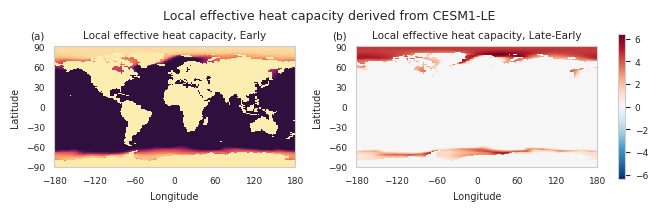

In [5]:
scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(6.47, 2),constrained_layout=True,subplot_kw={'projection': ccrs.PlateCarree()})


cbar_settings = {"shrink": 0.6, "label": ""}


#Annual
(heatcap_plot[:,:,80*12:105*12].mean('time')).plot(ax=ax1, add_colorbar=False, edgecolor='face', cmap=cmocean.cm.matter)
ax1.set_title('Local effective heat capacity, Early')
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_title('(b)', loc='left', x=-0.15)
#ax1.coastlines(resolution='110m', linewidth=1)
ax1.set_title('(a)',loc='left',x=-0.1)
ax1.set_xticks([-180,-120,-60,0,60,120,180])
ax1.set_yticks([-90,-60,-30,0,30,60,90])


(heatcap_plot[:,:,-126:].mean('time')-heatcap_plot[:,:,80*12:105*12].mean('time')).plot(ax=ax2, edgecolor='face', cmap='RdBu_r')
ax2.set_title('Local effective heat capacity, Late-Early')
#ax2.coastlines(resolution='110m', linewidth=1)
ax2.set_title('(b)',loc='left',x=-0.1)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_xticks([-180,-120,-60,0,60,120,180])
ax2.set_yticks([-90,-60,-30,0,30,60,90])



fig.suptitle('Local effective heat capacity derived from CESM1-LE',fontsize=18*scaling)

matplotlib.pyplot.savefig('heatcap_from_cesm_update_july2026_kimnorthparams.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)

# Zonal mean plot and feedback parameter

In [6]:
# made in variability_regression_ensoremoved

lambda_local=xr.open_dataset(cwd+"/data/variability_feedback_2000to2025_sst_oct2026.nc") #we checked this is exactly the same as "/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/variability_feedback_2000to2025_sst.nc"
lambda_local2=xr.open_dataset(cwd+"/data/variability_feedback_2075to2100_sst_oct2026.nc")

/glade/derecho/scratch/aurorabf/tmp/ipykernel_87424/1134038040.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()


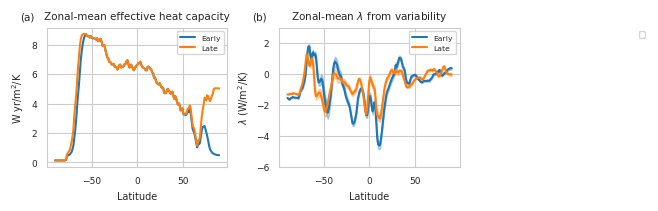

In [7]:
scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(6.47, 2),constrained_layout=True)

(heatcap_plot[:,:,80*12:105*12].mean('time').mean('lon')).plot(ax=ax1, color='tab:blue', label='Early')
(heatcap_plot[:,:,-126:].mean('time').mean('lon')).plot(ax=ax1, color='tab:orange', label='Late')
ax1.set_title('Zonal-mean effective heat capacity') 
ax1.set_ylabel('W yr/m$^2$/K')
ax1.set_xlabel('Latitude')
ax1.set_title('(a)', loc='left', x=-0.15)
ax1.legend()

(lambda_local.slope).plot(ax=ax2)
(lambda_local2.slope).plot(ax=ax2)
ax2.fill_between(lambda_local.lat, lambda_local.slope - lambda_local.stderr, lambda_local.slope + lambda_local.stderr, color='tab:blue', alpha=0.3)
ax2.fill_between(lambda_local2.lat, lambda_local2.slope - lambda_local2.stderr, lambda_local2.slope + lambda_local2.stderr, color='tab:orange', alpha=0.3)
ax2.set_xlabel('Latitude')
ax2.set_ylabel('$\lambda$ (W/m$^2$/K)')
ax2.set_title(r'Zonal-mean $\lambda$ from variability')
ax2.legend(['Early', 'Late']) 
ax2.set_title('(b)', loc='left', x=-0.15)
ax2.set_ylim([-6,3])



ax3.axis('off') 

ax3.set_title('')
ax3.set_xlabel('')

ax3.legend()

matplotlib.pyplot.savefig('parameters_from_cesm_update_oct2026_kimnorthparams_updated.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)


# Plot ensemble mean temperature. Used to be in make_plots.ipynb but have moved it here

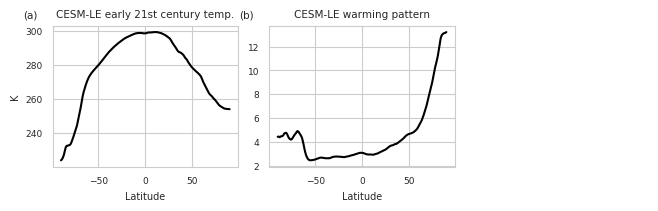

In [8]:
from matplotlib import rcParams

temp_sat=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_trefht_40members_CESM1.nc')
temp_sat=temp_sat.__xarray_dataarray_variable__
cesm_temps_mean=temp_sat.mean('ensemble_member')
cesm_temps_mean=cesm_temps_mean.mean('lon')
diff=cesm_temps_mean[-12*25:,:].mean(axis=0)-cesm_temps_mean[12*80:12*105,:].mean(axis=0)

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})


fig,((ax1,ax3,ax2))=plt.subplots(1,3,figsize=(6.47,2),constrained_layout=True)

cesm_temps_mean[12*80:12*105,:].mean(axis=0).plot(ax=ax1,color='black')
ax1.set_title('CESM-LE early 21st century temp.')
#ax1.set_ylim([0.1,1.2])
ax1.set_ylabel('K')
ax1.set_title('(a)',loc='left',x=-0.16)
ax1.set_xlabel('Latitude')


diff.plot(ax=ax3,color='black')
ax3.set_title('CESM-LE warming pattern')
#ax1.set_ylim([0.1,1.2])
ax3.set_ylabel('')
ax3.set_title('(b)',loc='left',x=-0.16)
ax3.set_xlabel('Latitude')





ax2.axis('off') 

ax2.set_title('')
ax2.set_xlabel('')





import matplotlib
matplotlib.pyplot.savefig('CESM1_pattern_updatedtitle23aug.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)

# Plotting heat capacity fitted from regression. 

Note that c and c_err were made in cesm1_heatcap_surfaceflux_constrainintercept_trefht_zonalmean_anomalies_yearly_withdeenso which isn't in this repo yet

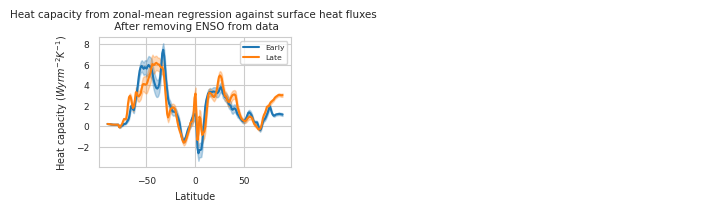

In [9]:
c=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/CESM1_heatcap_surfaceflux_constrainedintercept_trefht_slope_21stcentury_anom_yearly_zonalmean_aug_deenso.nc').__xarray_dataarray_variable__
c_err=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/CESM1_heatcap_surfaceflux_constrainedintercept_trefht_slopeerr_21stcentury_anom_yearly_zonalmean_aug_deenso.nc').__xarray_dataarray_variable__

#cesm1_heatcap_surfaceflux_constrainintercept_trefht_zonalmean_anomalies_yearly_withdeenso

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import rcParams


scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

fig, (ax,ax1,ax2) = plt.subplots(1, 3, figsize=(6.47, 2),constrained_layout=True)

c[0,:].plot(ax=ax)
c[-1,:].plot(ax=ax)

ax.fill_between(c.lat, c[0,:] - c_err[0,:], c[0,:] + c_err[0,:], color='tab:blue', alpha=0.3, label='±1 Standard Error')
ax.fill_between(c.lat, c[-1,:] - c_err[-1,:], c[-1,:] + c_err[-1,:], color='tab:orange', alpha=0.3, label='±1 Standard Error')
ax.set_xlabel('Latitude')
ax.set_ylabel('Heat capacity ($ W yr m^{-2} K^{-1}$)')
ax.set_title('Heat capacity from zonal-mean regression against surface heat fluxes \n After removing ENSO from data')

ax1.axis('off') 

ax1.set_title('')
ax1.set_xlabel('')

ax2.axis('off') 

ax2.set_title('')
ax2.set_xlabel('')

ax.legend(['Early','Late'])

matplotlib.pyplot.savefig('fitheatcap_aug2026.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)